# Teste brasileiro — cinco minutos

Resolução real de **cinco minutos**, horizonte **t+5 minutos**. Os nomes dos arquivos foram mantidos por solicitação do usuário; o conteúdo foi migrado de diário para intradiário.

O alvo e a persistência (t−5 min) precisam ser originalmente medidos. Cada etapa de preenchimento causal usa até 15 minutos; no Brasil a combinação proxy + ffill pode atingir 30 minutos somente no histórico: nunca se interpola usando ponto posterior. Não se concatenam blocos interrompidos. A avaliação principal é diurna (elevação solar > 0); a avaliação 24h é complementar. Zero noturno não deve inflar a precisão.

As entradas principais são potência AC em p.u., hora local e dia do ano em seno/cosseno. O vento continua excluído. ERA5 nativa horária é auxiliar e não entra nos modelos principais. Estatísticas de normalização vêm apenas do treino australiano; alvos de validação/teste não ajustam escalas.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
RAIZ=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/energia_transfer').is_dir())
if str(RAIZ/'src') not in sys.path: sys.path.insert(0,str(RAIZ/'src'))
PASTA=RAIZ/'experimentos/transfer_learning_australia_brasil'
AU=RAIZ/'experimentos/australia_deep_learning'
REPORT=RAIZ/'reports/intradiario'
from energia_transfer.transfer_learning.dados import carregar,particao
_,CONFIG,CONTRATO=carregar(PASTA)
def exibir(t): display(t.round(5))


{'alvos': 7668, 'primeiro': np.str_('2025-11-01T05:45:00'), 'ultimo': np.str_('2025-12-31T18:45:00'), 'alvos_cobertura_original_95': 7668, 'fracao_diurna_estimada_media_pct': 0.0, 'fracao_diurna_estimada_max_pct': 0.0, 'nota': 'Todos os alvos e persistências são medições originais; imputação somente no histórico. Avaliação principal diurna.'}
Avaliação 24h complementar: {'n': 14327, 'RMSE_kw_medio': 119.69793664855996}


,arquitetura,lag,metodo,n,sementes,MAE_kw_medio,RMSE_kw_medio,RMSE_kw_dp,nRMSE_capacidade_pct,R2_medio,skill_persistencia_pct
0,lstm_direta,6,cabeca,7668,5,93.18538,158.93075,0.25058,15.89308,0.77552,12.97242
1,lstm_direta,6,completo,7668,5,93.97997,157.45958,0.17214,15.74596,0.77965,13.77800
2,lstm_direta,6,local,7668,5,93.67967,157.36372,0.09919,15.73637,0.77992,13.83050
3,lstm_direta,6,sem_ajuste,7668,5,94.27984,160.02529,0.23154,16.00253,0.77241,12.37307
4,lstm_direta,12,cabeca,7668,5,93.38718,158.42461,0.26147,15.84246,0.77694,13.24957
5,lstm_direta,12,completo,7668,5,93.05536,157.02904,0.15137,15.70290,0.78086,14.01376
6,lstm_direta,12,local,7668,5,93.18185,156.96865,0.20608,15.69686,0.78102,14.04683
7,lstm_direta,12,sem_ajuste,7668,5,95.58356,159.31763,0.32058,15.93176,0.77442,12.76057
8,mlp_direta,6,cabeca,7668,5,93.20934,159.53675,0.29528,15.95368,0.77380,12.64058
9,mlp_direta,6,completo,7668,5,92.46131,157.94960,0.37852,15.79496,0.77828,13.50968


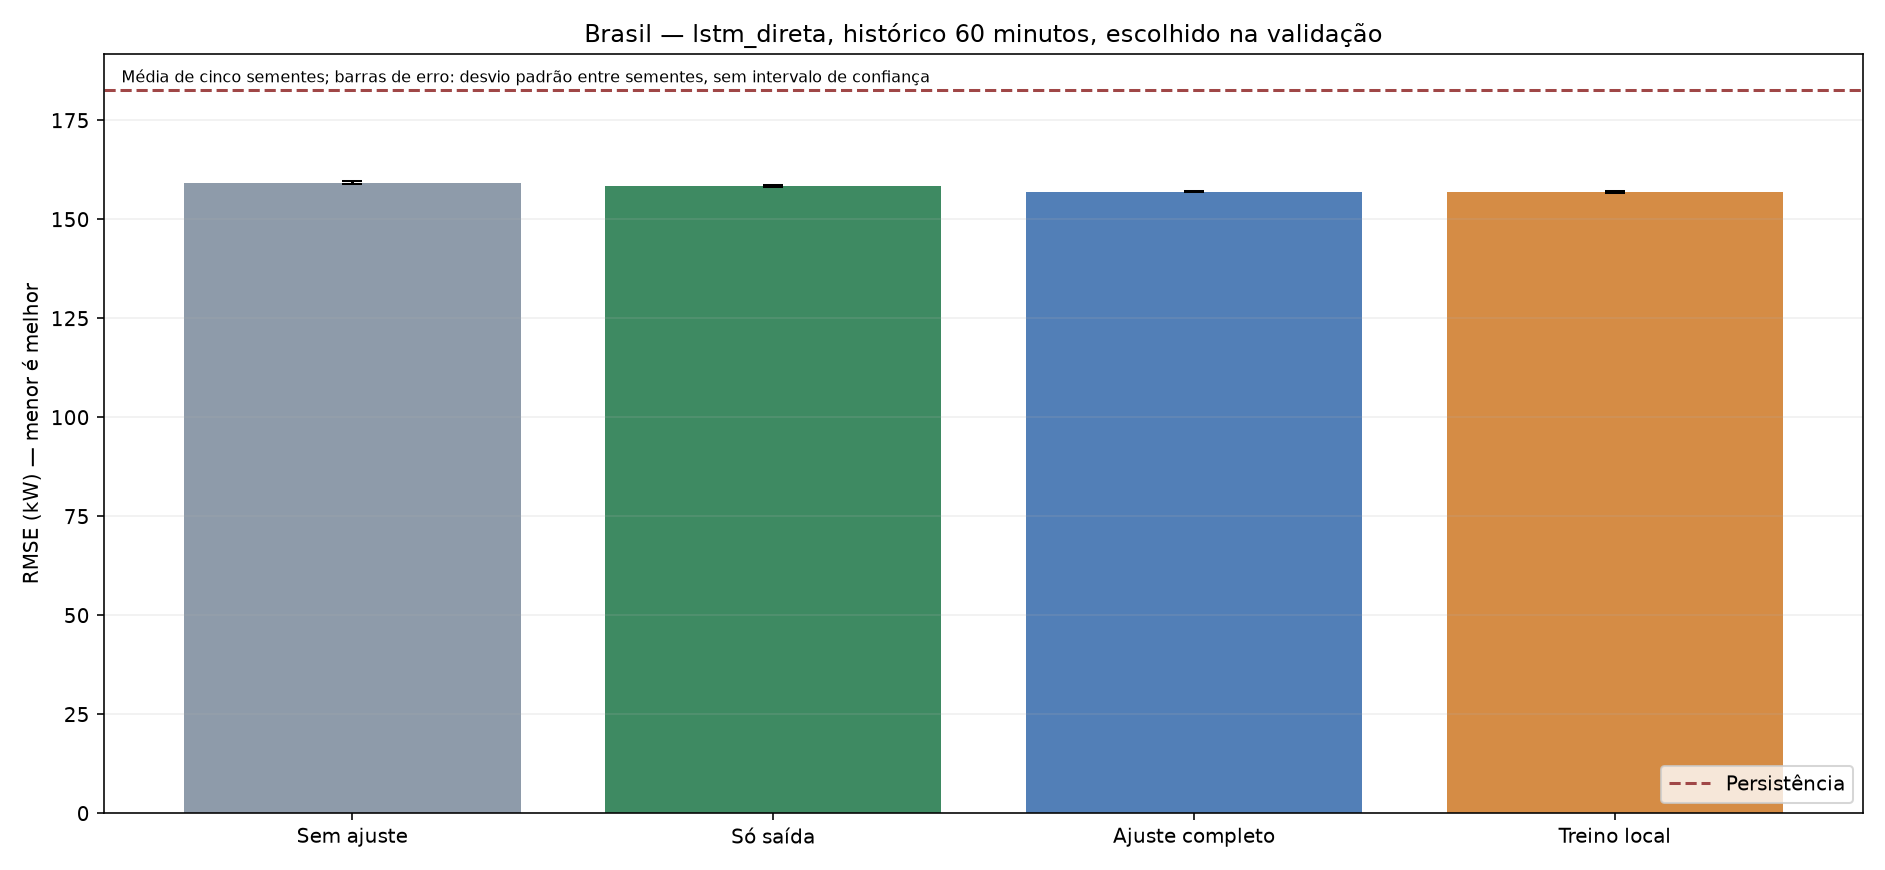

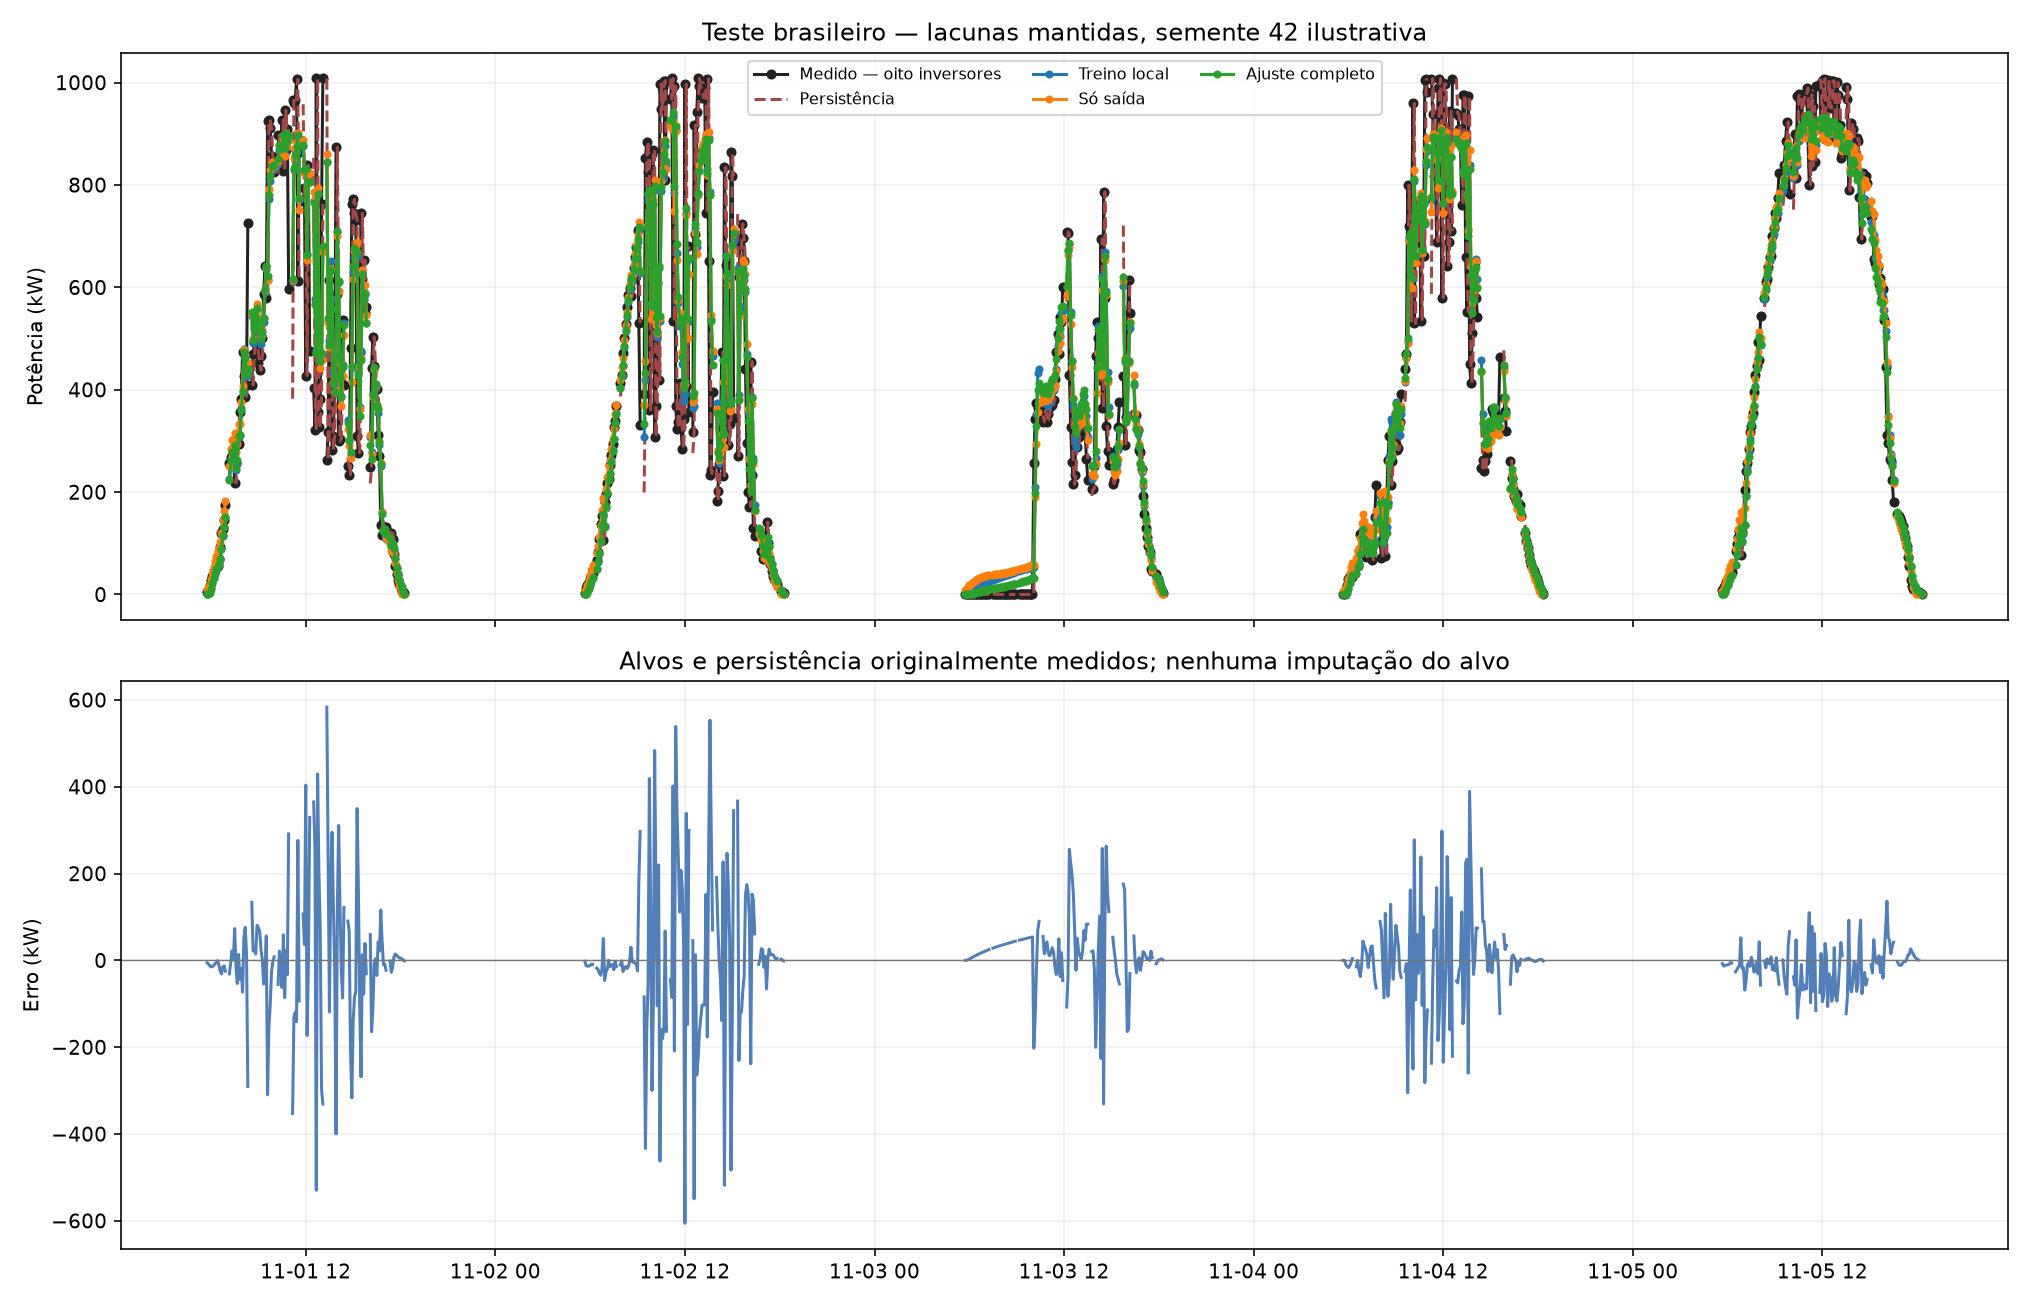

# Transferência Austrália → Brasil — resultado

Escolha pela validação: **lstm_direta**, lag **12**, método **local**.
A seleção considera médias de cinco sementes. O teste não muda a escolha; persistência pode ser a melhor opção operacional.
A validação favoreceu pesos treinados localmente. Não foi demonstrado benefício da transferência neste protocolo.
MAE da persistência: 91.201 kW; MAE da rede escolhida: 93.182 kW. A redução de RMSE não implica melhora em todas as métricas.


A rede escolhida teve redução de 0.00% no RMSE médio frente ao controle local da mesma arquitetura e lag. Valores negativos significam transferência pior que esse controle.
R² médio dessa rede no teste: 0.781. R² negativo indica erro quadrático maior que a referência descritiva da média dos alvos do próprio teste; essa média não é uma previsão disponível antecipadamente.
Não se troca a escolha por outra configuração que apareça melhor no teste. Ganho frente à persistência não demonstra por si só grande capacidade de generalização.

| Arquitetura | Lag | Método | MAE médio (kW) | RMSE médio (kW) | DP RMSE entre sementes | R² médio | Skill persistência (%) |
|---|---:|---|---:|---:|---:|---:|---:|
| lstm_direta | 6 | cabeca | 93.185 | 158.931 | 0.251 | 0.776 | 12.97 |
| lstm_direta | 6 | completo | 93.980 | 157.460 | 0.172 | 0.780 | 13.78 |
| lstm_direta | 6 | local | 93.680 | 157.364 | 0.099 | 0.780 | 13.83 |
| lstm_direta | 6 | sem_ajuste | 94.280 | 160.025 | 0.232 | 0.772 | 12.37 |
| lstm_direta | 12 | cabeca | 93.387 | 158.425 | 0.261 | 0.777 | 13.25 |
| lstm_direta | 12 | completo | 93.055 | 157.029 | 0.151 | 0.781 | 14.01 |
| lstm_direta | 12 | local | 93.182 | 156.969 | 0.206 | 0.781 | 14.05 |
| lstm_direta | 12 | sem_ajuste | 95.584 | 159.318 | 0.321 | 0.774 | 12.76 |
| mlp_direta | 6 | cabeca | 93.209 | 159.537 | 0.295 | 0.774 | 12.64 |
| mlp_direta | 6 | completo | 92.461 | 157.950 | 0.379 | 0.778 | 13.51 |
| mlp_direta | 6 | local | 94.556 | 157.777 | 0.532 | 0.779 | 13.60 |
| mlp_direta | 6 | sem_ajuste | 91.308 | 163.178 | 0.374 | 0.763 | 10.65 |
| mlp_direta | 12 | cabeca | 93.708 | 159.698 | 0.553 | 0.773 | 12.55 |
| mlp_direta | 12 | completo | 92.791 | 157.931 | 0.518 | 0.778 | 13.52 |
| mlp_direta | 12 | local | 95.567 | 157.684 | 0.552 | 0.779 | 13.65 |
| mlp_direta | 12 | sem_ajuste | 92.408 | 162.570 | 0.919 | 0.765 | 10.98 |
| mlp_residual | 6 | cabeca | 93.979 | 161.785 | 1.025 | 0.767 | 11.41 |
| mlp_residual | 6 | completo | 93.547 | 157.807 | 0.253 | 0.779 | 13.59 |
| mlp_residual | 6 | local | 92.894 | 158.008 | 0.463 | 0.778 | 13.48 |
| mlp_residual | 6 | sem_ajuste | 90.337 | 165.805 | 0.649 | 0.756 | 9.21 |
| mlp_residual | 12 | cabeca | 94.113 | 161.902 | 0.801 | 0.767 | 11.35 |
| mlp_residual | 12 | completo | 93.710 | 157.683 | 0.442 | 0.779 | 13.66 |
| mlp_residual | 12 | local | 92.761 | 157.840 | 0.574 | 0.779 | 13.57 |
| mlp_residual | 12 | sem_ajuste | 91.168 | 165.262 | 0.758 | 0.757 | 9.51 |
| persistencia | 0 | persistencia | 91.201 | 182.621 | nan | 0.704 | 0.00 |

Teste: 7668 alvos de 2025-11-01T05:45:00 a 2025-12-31T18:45:00, iguais para todos os métodos e lags.
Fração diurna estimada média: 0.00%; máxima: 0.00%.

![Comparação](../figuras/comparacao_transferencia.png)

![Previsões](../figuras/previsoes_brasil.png)

## Limitações

- Previsão t+5 minutos; avaliação principal diurna, sem zeros noturnos inflando a métrica.
- Janelas sobrepostas e erros autocorrelacionados; sementes não são intervalos de confiança temporal.
- Dados horários ERA5 apenas auxiliares, fora dos inputs principais.
- Treino fonte usa uma de cada 12 janelas válidas por custo de CPU; validação e teste mantêm todos os alvos elegíveis.
- Capacidades AC instaladas não representam capacidade operacional efetiva diária; falhas e mudanças DKA documentadas.

Avaliação complementar incluindo noite: {'n': 14327, 'RMSE_kw_medio': 119.69793664855996}. Não confundir com o teste diurno principal.

Treinos locais usam o mesmo contrato de normalização aprendido na fonte; diferem na inicialização dos pesos. Isso isola a transferência de pesos, sem oferecer ao controle um processamento incompatível.
Resultados da média das métricas de redes individuais; não são métricas de um ensemble. Ganho negativo indica pior desempenho que a referência.


In [2]:
from energia_transfer.transfer_learning.avaliacao import avaliar
resultado=avaliar(PASTA)
exibir(resultado['resumo'])
print(resultado['relatorio']['qualidade_alvos'])
print('Avaliação 24h complementar:',resultado['relatorio'].get('avaliacao_24h_complementar'))
display(Image(filename=str(PASTA/'figuras/comparacao_transferencia.png')))
display(Image(filename=str(PASTA/'figuras/previsoes_brasil.png')))
display(Markdown((PASTA/'resultados/relatorio.md').read_text(encoding='utf-8')))


As métricas principais usam apenas alvos diurnos originalmente medidos. O ganho contra persistência deve ser verificado; em cinco minutos esse benchmark costuma ser forte. Transferência pode ser negativa. As estatísticas de todo o teste, incluindo noite, são complementares e não substituem o resultado diurno. Capacidades e mudanças de configuração DKA estão documentadas em `fontes_e_hipoteses.json`.
